In [2]:
import pandas as pd
import numpy as np
import datetime as dt

In [3]:
main_df=pd.read_csv('prescription_dispensing_records.csv')

In [4]:
df=main_df.copy(deep=True)

In [5]:
df

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code
0,PAT000001,Amlodipine,4/11/2022,30,30,CVS0412,45115-354-69
1,PAT000001,Amlodipine,5/17/2022,30,30,CVS0199,33694-187-56
2,PAT000001,Amlodipine,6/17/2022,30,30,CVS0366,36106-401-64
3,PAT000001,Amlodipine,7/24/2022,30,30,CVS0125,43452-585-37
4,PAT000001,Amlodipine,8/22/2022,30,30,CVS0262,45223-680-86
...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,12/11/2022,30,30,CVS0285,53631-649-46
36266,PAT002999,Sertraline,1/18/2023,30,30,CVS0071,14557-505-11
36267,PAT003000,Levothyroxine,10/18/2022,90,30,CVS0070,96039-971-77
36268,PAT003000,Levothyroxine,1/21/2023,90,30,CVS0071,97081-655-71


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36270 entries, 0 to 36269
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   patient_id          36270 non-null  object
 1   drug_name           36270 non-null  object
 2   dispensing_date     36270 non-null  object
 3   days_supply         36270 non-null  int64 
 4   quantity_dispensed  36270 non-null  int64 
 5   pharmacy_id         36270 non-null  object
 6   ndc_code            36270 non-null  object
dtypes: int64(2), object(5)
memory usage: 1.9+ MB


In [7]:
df['patient_id'].unique().shape

(3000,)

### REFILL GAP



In [8]:
df['dispensing_date']=pd.to_datetime(df['dispensing_date'])

In [9]:
df['refill_days']= (df.groupby(['patient_id','drug_name'])['dispensing_date'].diff().dt.days)

In [10]:
df['refill_gap']=(df.groupby(['patient_id','drug_name'])['dispensing_date'].diff().dt.days)- (df['days_supply'])

In [11]:
df.head(20)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,NaN,NaN
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,-1.0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,NaN,NaN
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0


In [12]:
df.head(20)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,NaN,NaN
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,-1.0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,NaN,NaN
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0


In [13]:
df[['refill_days','refill_gap']]=df[['refill_days','refill_gap']].fillna(value=0)

In [14]:
df['refill_gap'][df['refill_gap']<0]

4       -1.0
13      -2.0
14      -2.0
15      -3.0
21      -2.0
        ... 
36246   -3.0
36247   -1.0
36251   -1.0
36264   -2.0
36265   -3.0
Name: refill_gap, Length: 7539, dtype: float64

In [15]:
df['early_refilling']=np.maximum(0,-df['refill_gap'])

In [16]:
df.head(20)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,-1.0,1.0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0,0.0
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0,0.0
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,0.0,0.0,-0.0
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0,0.0
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0,0.0


In [17]:
df['refill_gap']=df['refill_gap'].clip(lower=0)

In [18]:
df.head(10)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0,0.0
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0,0.0
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,0.0,0.0,-0.0
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0,0.0
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0,0.0


In [19]:
df[df['refill_gap']<0]

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling


In [20]:
avg_refill_gap=df.groupby(['patient_id','drug_name'])['refill_gap'].mean().reset_index()

In [21]:
avg_refill_gap=avg_refill_gap.rename(columns={'refill_gap':'avg_refill_gap'})

In [22]:
avg_refill_gap[avg_refill_gap['avg_refill_gap']<0]

,patient_id,drug_name,avg_refill_gap


In [23]:
avg_refill_gap

,patient_id,drug_name,avg_refill_gap
0,PAT000001,Amlodipine,2.714286
1,PAT000001,Levothyroxine,7.000000
2,PAT000001,Omeprazole,1.000000
3,PAT000002,Amlodipine,1.428571
4,PAT000002,Atorvastatin,5.000000
...,...,...,...
6016,PAT002998,Amlodipine,2.500000
6017,PAT002998,Levothyroxine,8.857143
6018,PAT002998,Metformin,10.000000
6019,PAT002999,Sertraline,2.166667


In [24]:
avg_gap=avg_refill_gap.groupby('patient_id')['avg_refill_gap'].mean().reset_index()

In [25]:
avg_gap

,patient_id,avg_refill_gap
0,PAT000001,3.571429
1,PAT000002,3.214286
2,PAT000003,0.000000
3,PAT000004,7.533333
4,PAT000005,12.300000
...,...,...
2995,PAT002996,0.666667
2996,PAT002997,2.083333
2997,PAT002998,7.119048
2998,PAT002999,2.166667


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='avg_refill_gap', ylabel='Count'>

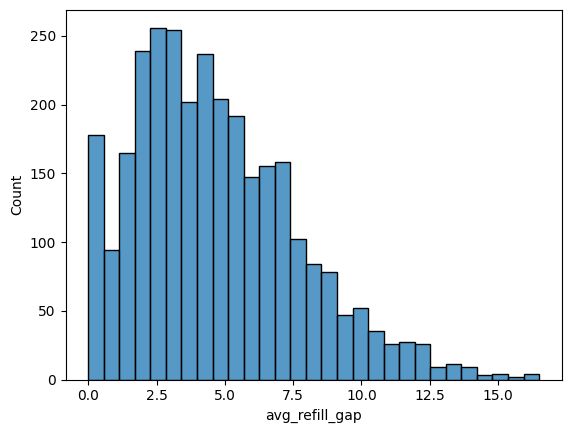

In [27]:
sns.histplot(avg_gap['avg_refill_gap'])

In [28]:
df['drug_name'].unique()

array(['Amlodipine', 'Levothyroxine', 'Omeprazole', 'Atorvastatin',
       'Metformin', 'Albuterol', 'Lisinopril', 'Sertraline'], dtype=object)

In [29]:
max_refill_gap=df.groupby(['patient_id','drug_name'])['refill_gap'].max().reset_index()

In [30]:
max_refill_gap

,patient_id,drug_name,refill_gap
0,PAT000001,Amlodipine,7.0
1,PAT000001,Levothyroxine,18.0
2,PAT000001,Omeprazole,5.0
3,PAT000002,Amlodipine,8.0
4,PAT000002,Atorvastatin,18.0
...,...,...,...
6016,PAT002998,Amlodipine,5.0
6017,PAT002998,Levothyroxine,19.0
6018,PAT002998,Metformin,26.0
6019,PAT002999,Sertraline,8.0


In [31]:
max_refill_gap=max_refill_gap.rename(columns={'refill_gap':'max_refill_gap'})

In [32]:
max_gap=max_refill_gap.groupby('patient_id')['max_refill_gap'].max().reset_index()
max_gap

,patient_id,max_refill_gap
0,PAT000001,18.0
1,PAT000002,18.0
2,PAT000003,0.0
3,PAT000004,24.0
4,PAT000005,24.0
...,...,...
2995,PAT002996,4.0
2996,PAT002997,11.0
2997,PAT002998,26.0
2998,PAT002999,8.0


<Axes: xlabel='max_refill_gap', ylabel='Count'>

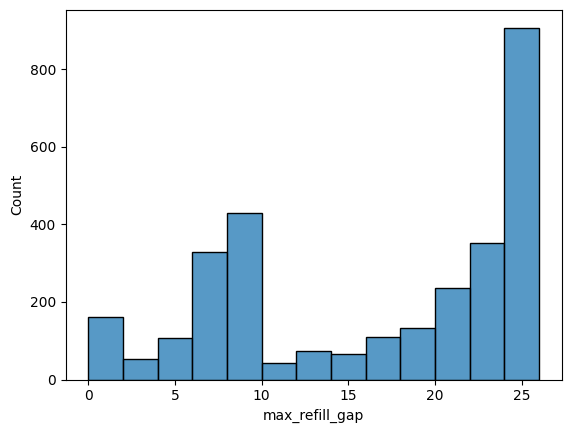

In [33]:
sns.histplot(max_gap['max_refill_gap'])

In [34]:
df.head(40)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0,0.0
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0,0.0
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,0.0,0.0,-0.0
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0,0.0
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0,0.0


In [35]:
df['late_refill']=df['refill_gap'].apply(lambda x: 1 if x>0 else 0)
df


,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,27.0,0.0,3.0,0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,38.0,8.0,0.0,1
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,0.0,0.0,-0.0,0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,95.0,5.0,0.0,1


In [36]:
df.groupby(['patient_id'])['late_refill'].sum().reset_index().rename(columns={'late_refill':'tot_late_refill'})

,patient_id,tot_late_refill
0,PAT000001,10
1,PAT000002,7
2,PAT000003,0
3,PAT000004,7
4,PAT000005,8
...,...,...
2995,PAT002996,1
2996,PAT002997,4
2997,PAT002998,8
2998,PAT002999,3


In [37]:
total_gap=df.groupby(['patient_id'])['refill_gap'].count().reset_index().rename(columns={'refill_gap':'tot_refill_gap'})
total_gap

,patient_id,tot_refill_gap
0,PAT000001,17
1,PAT000002,16
2,PAT000003,1
3,PAT000004,14
4,PAT000005,10
...,...,...
2995,PAT002996,6
2996,PAT002997,11
2997,PAT002998,12
2998,PAT002999,6


- we can delete these patient id since it has only one time visitation

In [38]:
to_remove=total_gap[total_gap['tot_refill_gap']==1]

In [39]:
to_remove

,patient_id,tot_refill_gap
2,PAT000003,1
54,PAT000055,1
63,PAT000064,1
109,PAT000110,1
171,PAT000172,1
...,...,...
2903,PAT002904,1
2945,PAT002946,1
2950,PAT002951,1
2965,PAT002966,1


In [40]:
df=df[~df['patient_id'].isin(to_remove['patient_id'])]

In [41]:
df

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,27.0,0.0,3.0,0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,38.0,8.0,0.0,1
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,0.0,0.0,-0.0,0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,95.0,5.0,0.0,1


In [42]:
total_late_refill=df.groupby(['patient_id'])['late_refill'].sum().reset_index().rename(columns={'late_refill':'tot_late_refill'})
total_late_refill

,patient_id,tot_late_refill
0,PAT000001,10
1,PAT000002,7
2,PAT000004,7
3,PAT000005,8
4,PAT000006,4
...,...,...
2905,PAT002996,1
2906,PAT002997,4
2907,PAT002998,8
2908,PAT002999,3


In [43]:
total_gap=df.groupby(['patient_id'])['refill_gap'].count().reset_index().rename(columns={'refill_gap':'tot_count_refill_gap'})
total_gap

,patient_id,tot_count_refill_gap
0,PAT000001,17
1,PAT000002,16
2,PAT000004,14
3,PAT000005,10
4,PAT000006,6
...,...,...
2905,PAT002996,6
2906,PAT002997,11
2907,PAT002998,12
2908,PAT002999,6


In [44]:
prop_late_refill = total_late_refill.merge(
    total_gap[['patient_id', 'tot_count_refill_gap']],
    on='patient_id',
    how='left'
)
prop_late_refill


,patient_id,tot_late_refill,tot_count_refill_gap
0,PAT000001,10,17
1,PAT000002,7,16
2,PAT000004,7,14
3,PAT000005,8,10
4,PAT000006,4,6
...,...,...,...
2905,PAT002996,1,6
2906,PAT002997,4,11
2907,PAT002998,8,12
2908,PAT002999,3,6


- pateint having high late refill per have high chance to stop the medication

In [45]:
prop_late_refill['late_refill_per'] = (
    (prop_late_refill['tot_late_refill'] / prop_late_refill['tot_count_refill_gap'])*100
)
prop_late_refill

,patient_id,tot_late_refill,tot_count_refill_gap,late_refill_per
0,PAT000001,10,17,58.823529
1,PAT000002,7,16,43.750000
2,PAT000004,7,14,50.000000
3,PAT000005,8,10,80.000000
4,PAT000006,4,6,66.666667
...,...,...,...,...
2905,PAT002996,1,6,16.666667
2906,PAT002997,4,11,36.363636
2907,PAT002998,8,12,66.666667
2908,PAT002999,3,6,50.000000


In [46]:
df

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,27.0,0.0,3.0,0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,38.0,8.0,0.0,1
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,0.0,0.0,-0.0,0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,95.0,5.0,0.0,1


In [47]:
avg_gap

,patient_id,avg_refill_gap
0,PAT000001,3.571429
1,PAT000002,3.214286
2,PAT000003,0.000000
3,PAT000004,7.533333
4,PAT000005,12.300000
...,...,...
2995,PAT002996,0.666667
2996,PAT002997,2.083333
2997,PAT002998,7.119048
2998,PAT002999,2.166667


In [48]:
max_gap

,patient_id,max_refill_gap
0,PAT000001,18.0
1,PAT000002,18.0
2,PAT000003,0.0
3,PAT000004,24.0
4,PAT000005,24.0
...,...,...
2995,PAT002996,4.0
2996,PAT002997,11.0
2997,PAT002998,26.0
2998,PAT002999,8.0


In [49]:
prop_late_refill

,patient_id,tot_late_refill,tot_count_refill_gap,late_refill_per
0,PAT000001,10,17,58.823529
1,PAT000002,7,16,43.750000
2,PAT000004,7,14,50.000000
3,PAT000005,8,10,80.000000
4,PAT000006,4,6,66.666667
...,...,...,...,...
2905,PAT002996,1,6,16.666667
2906,PAT002997,4,11,36.363636
2907,PAT002998,8,12,66.666667
2908,PAT002999,3,6,50.000000


In [50]:
final_df=avg_gap.merge(max_gap,on='patient_id',how='inner').merge(prop_late_refill,on='patient_id',how='inner')
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per
0,PAT000001,3.571429,18.0,10,17,58.823529
1,PAT000002,3.214286,18.0,7,16,43.750000
2,PAT000004,7.533333,24.0,7,14,50.000000
3,PAT000005,12.300000,24.0,8,10,80.000000
4,PAT000006,3.800000,24.0,4,6,66.666667
...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667
2906,PAT002997,2.083333,11.0,4,11,36.363636
2907,PAT002998,7.119048,26.0,8,12,66.666667
2908,PAT002999,2.166667,8.0,3,6,50.000000


In [51]:
df.head(50)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0,0.0,1
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0,0.0,1
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,0.0,0.0,-0.0,0
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0,0.0,1
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0,0.0,1


In [52]:
df.groupby('patient_id', as_index=False)['dispensing_date'].max()



,patient_id,dispensing_date
0,PAT000001,2023-02-03
1,PAT000002,2025-05-14
2,PAT000004,2024-08-30
3,PAT000005,2025-08-13
4,PAT000006,2023-12-25
...,...,...
2905,PAT002996,2023-10-09
2906,PAT002997,2024-05-22
2907,PAT002998,2024-04-16
2908,PAT002999,2023-01-18


In [53]:
idx = df.groupby('patient_id')['dispensing_date'].idxmax()

latest_records = df.loc[idx]

In [54]:
recent_gap=latest_records[['patient_id','refill_gap']].rename(columns={'refill_gap':'recent_refill_gap'})
recent_gap

,patient_id,recent_refill_gap
10,PAT000001,8.0
32,PAT000002,7.0
42,PAT000004,4.0
57,PAT000005,0.0
63,PAT000006,4.0
...,...,...
36237,PAT002996,0.0
36243,PAT002997,0.0
36255,PAT002998,19.0
36266,PAT002999,8.0


In [55]:
final_df=final_df.merge(recent_gap,on='patient_id',how='inner')
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0
...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0


In [56]:
df.head(50)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0,0.0,1
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0,0.0,1
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,0.0,0.0,-0.0,0
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0,0.0,1
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0,0.0,1


In [57]:
df.groupby('dispensing_date')['days_supply'].sum().reset_index()

,dispensing_date,days_supply
0,2022-01-01,210
1,2022-01-02,1410
2,2022-01-03,750
3,2022-01-04,1080
4,2022-01-05,150
...,...,...
1416,2026-02-15,90
1417,2026-03-03,90
1418,2026-03-04,180
1419,2026-03-14,90


In [58]:
df

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,27.0,0.0,3.0,0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,38.0,8.0,0.0,1
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,0.0,0.0,-0.0,0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,95.0,5.0,0.0,1


In [59]:
temp=df.groupby(['patient_id','drug_name'])[['refill_days','days_supply','refill_gap','early_refilling']].sum()

temp

refill_days  days_supply  refill_gap  \
patient_id drug_name                                             
PAT000001  Amlodipine           198.0          210        19.0   
           Levothyroxine        298.0          360        28.0   
           Omeprazole           149.0          180         6.0   
PAT000002  Amlodipine           188.0          210        10.0   
           Atorvastatin         747.0          810        45.0   
...                               ...          ...         ...   
PAT002998  Amlodipine            35.0           60         5.0   
           Levothyroxine        601.0          630        62.0   
           Metformin            210.0          270        30.0   
PAT002999  Sertraline           158.0          180        13.0   
PAT003000  Levothyroxine        211.0          270        31.0   

                          early_refilling  
patient_id drug_name                       
PAT000001  Amlodipine                 1.0  
           Levothyroxine              0.0  
           Omeprazole                 7.0  
PAT000002  Amlodipine                 2.0  
           Atorvastatin              18.0  
...                                   ...  
PAT002998  Amlodipine                 0.0  
           Levothyroxine              1.0  
           Metformin                  0.0  
PAT002999  Sertraline                 5.0  
PAT003000  Levothyroxine              0.0  

[5931 rows x 4 columns]

In [60]:
temp['unique_cov_days'] = (
    temp['days_supply'] - temp['early_refilling']
)
temp

refill_days  days_supply  refill_gap  \
patient_id drug_name                                             
PAT000001  Amlodipine           198.0          210        19.0   
           Levothyroxine        298.0          360        28.0   
           Omeprazole           149.0          180         6.0   
PAT000002  Amlodipine           188.0          210        10.0   
           Atorvastatin         747.0          810        45.0   
...                               ...          ...         ...   
PAT002998  Amlodipine            35.0           60         5.0   
           Levothyroxine        601.0          630        62.0   
           Metformin            210.0          270        30.0   
PAT002999  Sertraline           158.0          180        13.0   
PAT003000  Levothyroxine        211.0          270        31.0   

                          early_refilling  unique_cov_days  
patient_id drug_name                                        
PAT000001  Amlodipine                 1.0            209.0  
           Levothyroxine              0.0            360.0  
           Omeprazole                 7.0            173.0  
PAT000002  Amlodipine                 2.0            208.0  
           Atorvastatin              18.0            792.0  
...                                   ...              ...  
PAT002998  Amlodipine                 0.0             60.0  
           Levothyroxine              1.0            629.0  
           Metformin                  0.0            270.0  
PAT002999  Sertraline                 5.0            175.0  
PAT003000  Levothyroxine              0.0            270.0  

[5931 rows x 5 columns]

In [61]:
temp['unique_cov_days'] = (
    temp['days_supply'] - temp['early_refilling']
)
temp

refill_days  days_supply  refill_gap  \
patient_id drug_name                                             
PAT000001  Amlodipine           198.0          210        19.0   
           Levothyroxine        298.0          360        28.0   
           Omeprazole           149.0          180         6.0   
PAT000002  Amlodipine           188.0          210        10.0   
           Atorvastatin         747.0          810        45.0   
...                               ...          ...         ...   
PAT002998  Amlodipine            35.0           60         5.0   
           Levothyroxine        601.0          630        62.0   
           Metformin            210.0          270        30.0   
PAT002999  Sertraline           158.0          180        13.0   
PAT003000  Levothyroxine        211.0          270        31.0   

                          early_refilling  unique_cov_days  
patient_id drug_name                                        
PAT000001  Amlodipine                 1.0            209.0  
           Levothyroxine              0.0            360.0  
           Omeprazole                 7.0            173.0  
PAT000002  Amlodipine                 2.0            208.0  
           Atorvastatin              18.0            792.0  
...                                   ...              ...  
PAT002998  Amlodipine                 0.0             60.0  
           Levothyroxine              1.0            629.0  
           Metformin                  0.0            270.0  
PAT002999  Sertraline                 5.0            175.0  
PAT003000  Levothyroxine              0.0            270.0  

[5931 rows x 5 columns]

In [62]:
temp['observation_days'] = (
    temp['unique_cov_days'] + temp['refill_gap']
)
temp

refill_days  days_supply  refill_gap  \
patient_id drug_name                                             
PAT000001  Amlodipine           198.0          210        19.0   
           Levothyroxine        298.0          360        28.0   
           Omeprazole           149.0          180         6.0   
PAT000002  Amlodipine           188.0          210        10.0   
           Atorvastatin         747.0          810        45.0   
...                               ...          ...         ...   
PAT002998  Amlodipine            35.0           60         5.0   
           Levothyroxine        601.0          630        62.0   
           Metformin            210.0          270        30.0   
PAT002999  Sertraline           158.0          180        13.0   
PAT003000  Levothyroxine        211.0          270        31.0   

                          early_refilling  unique_cov_days  observation_days  
patient_id drug_name                                                          
PAT000001  Amlodipine                 1.0            209.0             228.0  
           Levothyroxine              0.0            360.0             388.0  
           Omeprazole                 7.0            173.0             179.0  
PAT000002  Amlodipine                 2.0            208.0             218.0  
           Atorvastatin              18.0            792.0             837.0  
...                                   ...              ...               ...  
PAT002998  Amlodipine                 0.0             60.0              65.0  
           Levothyroxine              1.0            629.0             691.0  
           Metformin                  0.0            270.0             300.0  
PAT002999  Sertraline                 5.0            175.0             188.0  
PAT003000  Levothyroxine              0.0            270.0             301.0  

[5931 rows x 6 columns]

In [63]:
temp['pdc'] = (
    temp['unique_cov_days'] /
    temp['observation_days']
)
temp

refill_days  days_supply  refill_gap  \
patient_id drug_name                                             
PAT000001  Amlodipine           198.0          210        19.0   
           Levothyroxine        298.0          360        28.0   
           Omeprazole           149.0          180         6.0   
PAT000002  Amlodipine           188.0          210        10.0   
           Atorvastatin         747.0          810        45.0   
...                               ...          ...         ...   
PAT002998  Amlodipine            35.0           60         5.0   
           Levothyroxine        601.0          630        62.0   
           Metformin            210.0          270        30.0   
PAT002999  Sertraline           158.0          180        13.0   
PAT003000  Levothyroxine        211.0          270        31.0   

                          early_refilling  unique_cov_days  observation_days  \
patient_id drug_name                                                           
PAT000001  Amlodipine                 1.0            209.0             228.0   
           Levothyroxine              0.0            360.0             388.0   
           Omeprazole                 7.0            173.0             179.0   
PAT000002  Amlodipine                 2.0            208.0             218.0   
           Atorvastatin              18.0            792.0             837.0   
...                                   ...              ...               ...   
PAT002998  Amlodipine                 0.0             60.0              65.0   
           Levothyroxine              1.0            629.0             691.0   
           Metformin                  0.0            270.0             300.0   
PAT002999  Sertraline                 5.0            175.0             188.0   
PAT003000  Levothyroxine              0.0            270.0             301.0   

                               pdc  
patient_id drug_name                
PAT000001  Amlodipine     0.916667  
           Levothyroxine  0.927835  
           Omeprazole     0.966480  
PAT000002  Amlodipine     0.954128  
           Atorvastatin   0.946237  
...                            ...  
PAT002998  Amlodipine     0.923077  
           Levothyroxine  0.910275  
           Metformin      0.900000  
PAT002999  Sertraline     0.930851  
PAT003000  Levothyroxine  0.897010  

[5931 rows x 7 columns]

In [64]:
patient_features = temp.groupby('patient_id')['pdc'].agg(
    mean_pdc='mean',
    min_pdc='min',
    max_pdc='max'
)
patient_features

,mean_pdc,min_pdc,max_pdc
patient_id,,,
PAT000001,0.936994,0.916667,0.966480
PAT000002,0.950182,0.946237,0.954128
PAT000004,0.921067,0.909931,0.932203
PAT000005,0.878698,0.878698,0.878698
PAT000006,0.961066,0.922131,1.000000
...,...,...,...
PAT002996,0.978142,0.978142,0.978142
PAT002997,0.955844,0.935897,0.975791
PAT002998,0.911117,0.900000,0.923077


In [65]:
df.head(20)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0
5,PAT000001,Amlodipine,2022-09-25,30,30,CVS0292,47647-161-23,34.0,4.0,0.0,1
6,PAT000001,Amlodipine,2022-10-26,30,30,CVS0230,23722-507-13,31.0,1.0,0.0,1
7,PAT000001,Levothyroxine,2022-04-11,90,30,CVS0471,45830-104-12,0.0,0.0,-0.0,0
8,PAT000001,Levothyroxine,2022-07-28,90,30,CVS0375,99184-458-57,108.0,18.0,0.0,1
9,PAT000001,Levothyroxine,2022-10-28,90,30,CVS0025,96062-226-40,92.0,2.0,0.0,1


In [66]:
df['start_date']=df['dispensing_date']

C:\Users\User\AppData\Local\Temp\ipykernel_9820\823576803.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['start_date']=df['dispensing_date']


In [67]:
df['end_date']=(
    df['dispensing_date']+pd.to_timedelta(df['days_supply'],unit='D')
)

C:\Users\User\AppData\Local\Temp\ipykernel_9820\2039490684.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['end_date']=(


In [68]:
df

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill,start_date,end_date
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0,2022-04-11,2022-05-11
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1,2022-05-17,2022-06-16
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1,2022-06-17,2022-07-17
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1,2022-07-24,2022-08-23
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0,2022-08-22,2022-09-21
...,...,...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,27.0,0.0,3.0,0,2022-12-11,2023-01-10
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,38.0,8.0,0.0,1,2023-01-18,2023-02-17
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,0.0,0.0,-0.0,0,2022-10-18,2023-01-16
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,95.0,5.0,0.0,1,2023-01-21,2023-04-21


In [69]:
df = df.sort_values(
    ['patient_id', 'drug_name', 'start_date']
)

In [70]:
df.head(
    
)

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill,start_date,end_date
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0,2022-04-11,2022-05-11
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1,2022-05-17,2022-06-16
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1,2022-06-17,2022-07-17
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1,2022-07-24,2022-08-23
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0,2022-08-22,2022-09-21


In [71]:
df.groupby(['patient_id','drug_name'])

In [72]:
def merge_intervals(group):

    intervals = (
        group[['start_date', 'end_date']]
        .sort_values('start_date')
        .values
    )

    merged = []

    for start, end in intervals:

        start = pd.Timestamp(start)
        end = pd.Timestamp(end)

        # First interval
        if not merged:
            merged.append([start, end])

        # Overlapping interval
        elif start <= merged[-1][1]:
            merged[-1][1] = max(
                merged[-1][1],
                end
            )

        # Non-overlapping interval
        else:
            merged.append([start, end])

    return merged

In [73]:
coverage = (
    df.groupby(['patient_id', 'drug_name'])
      .apply(merge_intervals)
      .reset_index(name='merged_intervals')
)

C:\Users\User\AppData\Local\Temp\ipykernel_9820\2656228135.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(merge_intervals)


In [74]:
coverage

,patient_id,drug_name,merged_intervals
0,PAT000001,Amlodipine,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [..."
1,PAT000001,Levothyroxine,"[[2022-04-11 00:00:00, 2022-07-10 00:00:00], [..."
2,PAT000001,Omeprazole,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [..."
3,PAT000002,Amlodipine,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [..."
4,PAT000002,Atorvastatin,"[[2023-04-28 00:00:00, 2023-10-20 00:00:00], [..."
...,...,...,...
5926,PAT002998,Amlodipine,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [..."
5927,PAT002998,Levothyroxine,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [..."
5928,PAT002998,Metformin,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [..."
5929,PAT002999,Sertraline,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [..."


In [75]:
def calculate_covered_days(intervals):

    total_days = 0

    for start, end in intervals:
        total_days += (end - start).days

    return total_days

In [76]:
coverage['unique_covered_days'] = (
    coverage['merged_intervals']
    .apply(calculate_covered_days)
)

In [77]:
coverage

,patient_id,drug_name,merged_intervals,unique_covered_days
0,PAT000001,Amlodipine,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",209
1,PAT000001,Levothyroxine,"[[2022-04-11 00:00:00, 2022-07-10 00:00:00], [...",360
2,PAT000001,Omeprazole,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",173
3,PAT000002,Amlodipine,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...",208
4,PAT000002,Atorvastatin,"[[2023-04-28 00:00:00, 2023-10-20 00:00:00], [...",792
...,...,...,...,...
5926,PAT002998,Amlodipine,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...",60
5927,PAT002998,Levothyroxine,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",629
5928,PAT002998,Metformin,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",270
5929,PAT002999,Sertraline,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",175


In [78]:
def calculate_observation_days(intervals):

    first_start = intervals[0][0]
    last_end = intervals[-1][1]

    observation_days = (last_end - first_start).days

    return observation_days

In [79]:
coverage['total_observation_days'] = (
    coverage['merged_intervals']
    .apply(calculate_observation_days)
)

In [80]:
coverage

,patient_id,drug_name,merged_intervals,unique_covered_days,total_observation_days
0,PAT000001,Amlodipine,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",209,228
1,PAT000001,Levothyroxine,"[[2022-04-11 00:00:00, 2022-07-10 00:00:00], [...",360,388
2,PAT000001,Omeprazole,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",173,179
3,PAT000002,Amlodipine,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...",208,218
4,PAT000002,Atorvastatin,"[[2023-04-28 00:00:00, 2023-10-20 00:00:00], [...",792,837
...,...,...,...,...,...
5926,PAT002998,Amlodipine,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...",60,65
5927,PAT002998,Levothyroxine,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",629,691
5928,PAT002998,Metformin,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",270,300
5929,PAT002999,Sertraline,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",175,188


In [81]:
patient_intervals = (
    coverage
    .groupby('patient_id')['merged_intervals']
    .apply(lambda x: [interval for intervals in x for interval in intervals])
    .reset_index(name='all_intervals')
)

In [82]:
def merge_intervals_list(intervals):

    intervals = sorted(intervals, key=lambda x: x[0])

    merged = []

    for start, end in intervals:

        if not merged:
            merged.append([start, end])

        elif start <= merged[-1][1]:
            merged[-1][1] = max(
                merged[-1][1],
                end
            )

        else:
            merged.append([start, end])

    return merged

In [83]:
patient_intervals['merged_patient_intervals'] = (
    patient_intervals['all_intervals']
    .apply(merge_intervals_list)
)

In [84]:
def calculate_observation_days(intervals):

    first_start = intervals[0][0]
    last_end = intervals[-1][1]

    return (last_end - first_start).days

In [85]:
patient_intervals['total_observation_days'] = (
    patient_intervals['merged_patient_intervals']
    .apply(calculate_observation_days)
)

In [86]:
patient_intervals

,patient_id,all_intervals,merged_patient_intervals,total_observation_days
0,PAT000001,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...","[[2022-04-11 00:00:00, 2023-01-26 00:00:00], [...",388
1,PAT000002,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...","[[2023-04-28 00:00:00, 2024-04-26 00:00:00], [...",837
2,PAT000004,"[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...","[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...",866
3,PAT000005,"[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...","[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...",1014
4,PAT000006,"[[2022-11-22 00:00:00, 2022-12-22 00:00:00], [...","[[2022-11-22 00:00:00, 2023-02-20 00:00:00], [...",488
...,...,...,...,...
2905,PAT002996,"[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...","[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...",183
2906,PAT002997,"[[2023-03-02 00:00:00, 2023-05-31 00:00:00], [...","[[2023-03-02 00:00:00, 2024-02-28 00:00:00], [...",537
2907,PAT002998,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...","[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",691
2908,PAT002999,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...","[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",188


In [87]:
coverage.groupby('patient_id')[['unique_covered_days','total_observation_days']].max('total_observation_days')

,unique_covered_days,total_observation_days
patient_id,,
PAT000001,360,388
PAT000002,792,837
PAT000004,788,866
PAT000005,891,1014
PAT000006,450,488
...,...,...
PAT002996,179,183
PAT002997,524,537
PAT002998,629,691


In [88]:
patient_intervals['unique_covered_days'] = (
    patient_intervals['merged_patient_intervals']
    .apply(calculate_covered_days)
)

In [89]:
patient_intervals

,patient_id,all_intervals,merged_patient_intervals,total_observation_days,unique_covered_days
0,PAT000001,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...","[[2022-04-11 00:00:00, 2023-01-26 00:00:00], [...",388,380
1,PAT000002,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...","[[2023-04-28 00:00:00, 2024-04-26 00:00:00], [...",837,804
2,PAT000004,"[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...","[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...",866,834
3,PAT000005,"[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...","[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...",1014,891
4,PAT000006,"[[2022-11-22 00:00:00, 2022-12-22 00:00:00], [...","[[2022-11-22 00:00:00, 2023-02-20 00:00:00], [...",488,450
...,...,...,...,...,...
2905,PAT002996,"[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...","[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...",183,179
2906,PAT002997,"[[2023-03-02 00:00:00, 2023-05-31 00:00:00], [...","[[2023-03-02 00:00:00, 2024-02-28 00:00:00], [...",537,535
2907,PAT002998,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...","[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",691,651
2908,PAT002999,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...","[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",188,175


In [90]:
patient_intervals['pdc'] = (
    patient_intervals['unique_covered_days']
    /
    patient_intervals['total_observation_days']
)

In [91]:
patient_intervals

,patient_id,all_intervals,merged_patient_intervals,total_observation_days,unique_covered_days,pdc
0,PAT000001,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...","[[2022-04-11 00:00:00, 2023-01-26 00:00:00], [...",388,380,0.979381
1,PAT000002,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...","[[2023-04-28 00:00:00, 2024-04-26 00:00:00], [...",837,804,0.960573
2,PAT000004,"[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...","[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...",866,834,0.963048
3,PAT000005,"[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...","[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...",1014,891,0.878698
4,PAT000006,"[[2022-11-22 00:00:00, 2022-12-22 00:00:00], [...","[[2022-11-22 00:00:00, 2023-02-20 00:00:00], [...",488,450,0.922131
...,...,...,...,...,...,...
2905,PAT002996,"[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...","[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...",183,179,0.978142
2906,PAT002997,"[[2023-03-02 00:00:00, 2023-05-31 00:00:00], [...","[[2023-03-02 00:00:00, 2024-02-28 00:00:00], [...",537,535,0.996276
2907,PAT002998,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...","[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",691,651,0.942113
2908,PAT002999,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...","[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",188,175,0.930851


In [92]:
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0
...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0


In [93]:
df = df.sort_values(
    ['patient_id', 'drug_name', 'dispensing_date']
)
df

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill,start_date,end_date
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0,2022-04-11,2022-05-11
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1,2022-05-17,2022-06-16
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1,2022-06-17,2022-07-17
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1,2022-07-24,2022-08-23
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0,2022-08-22,2022-09-21
...,...,...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,27.0,0.0,3.0,0,2022-12-11,2023-01-10
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,38.0,8.0,0.0,1,2023-01-18,2023-02-17
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,0.0,0.0,-0.0,0,2022-10-18,2023-01-16
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,95.0,5.0,0.0,1,2023-01-21,2023-04-21


In [94]:
df = df.sort_values(
    ['patient_id', 'drug_name', 'dispensing_date']
)

In [95]:
df['next_dispensing_date'] = (
    df.groupby(['patient_id', 'drug_name'])
      ['dispensing_date']
      .shift(-1)
)

In [96]:
df['uncovered_gap'] = (
    df['next_dispensing_date'] - df['end_date']
).dt.days.clip(lower=0)

In [97]:
df

,patient_id,drug_name,dispensing_date,days_supply,quantity_dispensed,pharmacy_id,ndc_code,refill_days,refill_gap,early_refilling,late_refill,start_date,end_date,next_dispensing_date,uncovered_gap
0,PAT000001,Amlodipine,2022-04-11,30,30,CVS0412,45115-354-69,0.0,0.0,-0.0,0,2022-04-11,2022-05-11,2022-05-17,6.0
1,PAT000001,Amlodipine,2022-05-17,30,30,CVS0199,33694-187-56,36.0,6.0,0.0,1,2022-05-17,2022-06-16,2022-06-17,1.0
2,PAT000001,Amlodipine,2022-06-17,30,30,CVS0366,36106-401-64,31.0,1.0,0.0,1,2022-06-17,2022-07-17,2022-07-24,7.0
3,PAT000001,Amlodipine,2022-07-24,30,30,CVS0125,43452-585-37,37.0,7.0,0.0,1,2022-07-24,2022-08-23,2022-08-22,0.0
4,PAT000001,Amlodipine,2022-08-22,30,30,CVS0262,45223-680-86,29.0,0.0,1.0,0,2022-08-22,2022-09-21,2022-09-25,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36265,PAT002999,Sertraline,2022-12-11,30,30,CVS0285,53631-649-46,27.0,0.0,3.0,0,2022-12-11,2023-01-10,2023-01-18,8.0
36266,PAT002999,Sertraline,2023-01-18,30,30,CVS0071,14557-505-11,38.0,8.0,0.0,1,2023-01-18,2023-02-17,NaT,NaN
36267,PAT003000,Levothyroxine,2022-10-18,90,30,CVS0070,96039-971-77,0.0,0.0,-0.0,0,2022-10-18,2023-01-16,2023-01-21,5.0
36268,PAT003000,Levothyroxine,2023-01-21,90,30,CVS0071,97081-655-71,95.0,5.0,0.0,1,2023-01-21,2023-04-21,2023-05-17,26.0


In [98]:
coverage

,patient_id,drug_name,merged_intervals,unique_covered_days,total_observation_days
0,PAT000001,Amlodipine,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",209,228
1,PAT000001,Levothyroxine,"[[2022-04-11 00:00:00, 2022-07-10 00:00:00], [...",360,388
2,PAT000001,Omeprazole,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",173,179
3,PAT000002,Amlodipine,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...",208,218
4,PAT000002,Atorvastatin,"[[2023-04-28 00:00:00, 2023-10-20 00:00:00], [...",792,837
...,...,...,...,...,...
5926,PAT002998,Amlodipine,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...",60,65
5927,PAT002998,Levothyroxine,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",629,691
5928,PAT002998,Metformin,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",270,300
5929,PAT002999,Sertraline,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",175,188


In [99]:
final_df=final_df.merge(patient_intervals,on='patient_id',how='inner')
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap,all_intervals,merged_patient_intervals,total_observation_days,unique_covered_days,pdc
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...","[[2022-04-11 00:00:00, 2023-01-26 00:00:00], [...",388,380,0.979381
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...","[[2023-04-28 00:00:00, 2024-04-26 00:00:00], [...",837,804,0.960573
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0,"[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...","[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...",866,834,0.963048
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0,"[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...","[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...",1014,891,0.878698
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0,"[[2022-11-22 00:00:00, 2022-12-22 00:00:00], [...","[[2022-11-22 00:00:00, 2023-02-20 00:00:00], [...",488,450,0.922131
...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0,"[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...","[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...",183,179,0.978142
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0,"[[2023-03-02 00:00:00, 2023-05-31 00:00:00], [...","[[2023-03-02 00:00:00, 2024-02-28 00:00:00], [...",537,535,0.996276
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...","[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",691,651,0.942113
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...","[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",188,175,0.930851


In [100]:
days_supply=df.groupby('patient_id')['days_supply'].sum('days_supply')
days_supply

patient_id
PAT000001     750
PAT000002    1020
PAT000004    1260
PAT000005     900
PAT000006     480
             ... 
PAT002996     180
PAT002997     690
PAT002998     960
PAT002999     180
PAT003000     270
Name: days_supply, Length: 2910, dtype: int64

In [101]:
final_df=final_df.merge(days_supply,on='patient_id',how='inner')
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap,all_intervals,merged_patient_intervals,total_observation_days,unique_covered_days,pdc,days_supply
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...","[[2022-04-11 00:00:00, 2023-01-26 00:00:00], [...",388,380,0.979381,750
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...","[[2023-04-28 00:00:00, 2024-04-26 00:00:00], [...",837,804,0.960573,1020
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0,"[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...","[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...",866,834,0.963048,1260
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0,"[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...","[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...",1014,891,0.878698,900
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0,"[[2022-11-22 00:00:00, 2022-12-22 00:00:00], [...","[[2022-11-22 00:00:00, 2023-02-20 00:00:00], [...",488,450,0.922131,480
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0,"[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...","[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...",183,179,0.978142,180
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0,"[[2023-03-02 00:00:00, 2023-05-31 00:00:00], [...","[[2023-03-02 00:00:00, 2024-02-28 00:00:00], [...",537,535,0.996276,690
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...","[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",691,651,0.942113,960
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...","[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",188,175,0.930851,180


In [102]:
final_df['CMA']=final_df['days_supply']/final_df['total_observation_days']
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap,all_intervals,merged_patient_intervals,total_observation_days,unique_covered_days,pdc,days_supply,CMA
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...","[[2022-04-11 00:00:00, 2023-01-26 00:00:00], [...",388,380,0.979381,750,1.932990
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...","[[2023-04-28 00:00:00, 2024-04-26 00:00:00], [...",837,804,0.960573,1020,1.218638
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0,"[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...","[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...",866,834,0.963048,1260,1.454965
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0,"[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...","[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...",1014,891,0.878698,900,0.887574
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0,"[[2022-11-22 00:00:00, 2022-12-22 00:00:00], [...","[[2022-11-22 00:00:00, 2023-02-20 00:00:00], [...",488,450,0.922131,480,0.983607
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0,"[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...","[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...",183,179,0.978142,180,0.983607
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0,"[[2023-03-02 00:00:00, 2023-05-31 00:00:00], [...","[[2023-03-02 00:00:00, 2024-02-28 00:00:00], [...",537,535,0.996276,690,1.284916
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...","[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",691,651,0.942113,960,1.389291
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...","[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",188,175,0.930851,180,0.957447


In [103]:
final_df['CMG']=1-final_df['pdc']
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap,all_intervals,merged_patient_intervals,total_observation_days,unique_covered_days,pdc,days_supply,CMA,CMG
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...","[[2022-04-11 00:00:00, 2023-01-26 00:00:00], [...",388,380,0.979381,750,1.932990,0.020619
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...","[[2023-04-28 00:00:00, 2024-04-26 00:00:00], [...",837,804,0.960573,1020,1.218638,0.039427
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0,"[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...","[[2022-07-16 00:00:00, 2023-01-08 00:00:00], [...",866,834,0.963048,1260,1.454965,0.036952
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0,"[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...","[[2023-02-01 00:00:00, 2023-05-02 00:00:00], [...",1014,891,0.878698,900,0.887574,0.121302
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0,"[[2022-11-22 00:00:00, 2022-12-22 00:00:00], [...","[[2022-11-22 00:00:00, 2023-02-20 00:00:00], [...",488,450,0.922131,480,0.983607,0.077869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0,"[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...","[[2023-05-09 00:00:00, 2023-06-08 00:00:00], [...",183,179,0.978142,180,0.983607,0.021858
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0,"[[2023-03-02 00:00:00, 2023-05-31 00:00:00], [...","[[2023-03-02 00:00:00, 2024-02-28 00:00:00], [...",537,535,0.996276,690,1.284916,0.003724
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...","[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",691,651,0.942113,960,1.389291,0.057887
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...","[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",188,175,0.930851,180,0.957447,0.069149


In [104]:
final_df=final_df.drop(
    ['all_intervals','merged_patient_intervals'],axis=1
)
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap,total_observation_days,unique_covered_days,pdc,days_supply,CMA,CMG
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0,388,380,0.979381,750,1.932990,0.020619
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0,837,804,0.960573,1020,1.218638,0.039427
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0,866,834,0.963048,1260,1.454965,0.036952
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0,1014,891,0.878698,900,0.887574,0.121302
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0,488,450,0.922131,480,0.983607,0.077869
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0,183,179,0.978142,180,0.983607,0.021858
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0,537,535,0.996276,690,1.284916,0.003724
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0,691,651,0.942113,960,1.389291,0.057887
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0,188,175,0.930851,180,0.957447,0.069149


In [105]:
final_df

,patient_id,avg_refill_gap,max_refill_gap,tot_late_refill,tot_count_refill_gap,late_refill_per,recent_refill_gap,total_observation_days,unique_covered_days,pdc,days_supply,CMA,CMG
0,PAT000001,3.571429,18.0,10,17,58.823529,8.0,388,380,0.979381,750,1.932990,0.020619
1,PAT000002,3.214286,18.0,7,16,43.750000,7.0,837,804,0.960573,1020,1.218638,0.039427
2,PAT000004,7.533333,24.0,7,14,50.000000,4.0,866,834,0.963048,1260,1.454965,0.036952
3,PAT000005,12.300000,24.0,8,10,80.000000,0.0,1014,891,0.878698,900,0.887574,0.121302
4,PAT000006,3.800000,24.0,4,6,66.666667,4.0,488,450,0.922131,480,0.983607,0.077869
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2905,PAT002996,0.666667,4.0,1,6,16.666667,0.0,183,179,0.978142,180,0.983607,0.021858
2906,PAT002997,2.083333,11.0,4,11,36.363636,0.0,537,535,0.996276,690,1.284916,0.003724
2907,PAT002998,7.119048,26.0,8,12,66.666667,19.0,691,651,0.942113,960,1.389291,0.057887
2908,PAT002999,2.166667,8.0,3,6,50.000000,8.0,188,175,0.930851,180,0.957447,0.069149


In [106]:
feature_engineered_df=final_df.copy(deep=True)

In [107]:
feature_engineered_df.to_csv('feature_engineered_df.csv',index=False)


In [109]:
coverage['pdc']=coverage['unique_covered_days']/coverage['total_observation_days']

In [110]:
coverage

,patient_id,drug_name,merged_intervals,unique_covered_days,total_observation_days,pdc
0,PAT000001,Amlodipine,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",209,228,0.916667
1,PAT000001,Levothyroxine,"[[2022-04-11 00:00:00, 2022-07-10 00:00:00], [...",360,388,0.927835
2,PAT000001,Omeprazole,"[[2022-04-11 00:00:00, 2022-05-11 00:00:00], [...",173,179,0.966480
3,PAT000002,Amlodipine,"[[2023-04-28 00:00:00, 2023-07-27 00:00:00], [...",208,218,0.954128
4,PAT000002,Atorvastatin,"[[2023-04-28 00:00:00, 2023-10-20 00:00:00], [...",792,837,0.946237
...,...,...,...,...,...,...
5926,PAT002998,Amlodipine,"[[2022-08-24 00:00:00, 2022-09-23 00:00:00], [...",60,65,0.923077
5927,PAT002998,Levothyroxine,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",629,691,0.910275
5928,PAT002998,Metformin,"[[2022-08-24 00:00:00, 2022-11-22 00:00:00], [...",270,300,0.900000
5929,PAT002999,Sertraline,"[[2022-08-13 00:00:00, 2022-09-12 00:00:00], [...",175,188,0.930851


In [111]:
coverage.to_csv('drug_level_pdc.csv',index=False)